# Unsupervised Machine Learning Workshop

In this workshop you will practice **unsupervised learning** — discovering structure in data without predefined labels. You will work in groups, with each member running a different clustering algorithm as a parallel experiment on its own Git branch. At the end, you will compare results through Pull Requests.

### Why unsupervised learning?

When you don't have labeled data, unsupervised algorithms can find **natural groupings**, reduce dimensionality, and detect anomalies. The challenge: *how do you know if the algorithm learned something useful?* That is what this workshop is about.

### Choose your dataset

**Option A (recommended):** Use a dataset related to your own project. Any tabular CSV with at least 2-3 numerical columns will work.

**Option B:** Use one of these classic clustering datasets:

| Dataset | Rows | Features | Why it works well | Link |
|---------|------|----------|-------------------|------|
| Mall Customers | 200 | 5 (Age, Income, Spending Score) | Different scales, clear segments | [Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) |
| Wholesale Customers | 440 | 8 (spending across product categories) | Multi-dimensional, real purchasing data | [UCI ML Repository](https://archive.ics.uci.edu/dataset/292/wholesale+customers) |
| Penguins | 344 | 4 numeric + species label (ignore for clustering, use to validate) | Clean, small, good for beginners | `sns.load_dataset('penguins')` — built into seaborn |

### How this workshop works

- Exercises are marked with difficulty: \*  (basic), \*\* (intermediate), \*\*\* (challenge)
- Everyone should complete the \* exercises
- **Parts 0 and 1 are done together as a group** on the `main` branch
- **Part 2 is done individually** — each group member picks one algorithm and works on a separate branch
- **Parts 3-4** bring the group back together to compare and synthesize

---

---
## Part 0: Repository & Group Setup (~10 min)

You will practice a collaborative GitHub workflow: **one fork per group**, separate branches for each experiment, Pull Requests to compare and merge.

### Step 1 — One person forks the repository

One group member forks the workshop repository on GitHub and **adds the other members as collaborators** (Settings → Collaborators).

### Step 2 — Everyone clones the same fork

```bash
git clone https://github.com/<FORK-OWNER>/Workshop-UML.git
cd Workshop-UML
```

### Step 3 — Stay on `main` for now

Parts 0 and 1 are shared work. You will create individual branches in Part 2.

---

## Setup

Run this cell to import libraries. If any are missing, install with `pip install <package>`.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage

# Nicer defaults
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 20)

print("All imports OK")

All imports OK


---
## Part 1: Data Preparation & Scaling (~20 min)

**Do this together as a group on `main`.** Everyone should have the same clean, scaled dataset before branching out.

Clustering algorithms are sensitive to the **scale** of features. If one column ranges from 0-100 and another from 0-100,000, the large-range column will dominate distance calculations, and the algorithm will essentially ignore the small-range column.

### Exercise 1.1 * — Load and inspect

Load your dataset and get oriented:
- How many rows and columns?
- Which columns are numerical? Which are categorical?
- Are there missing values? (Handle them now — clustering algorithms typically can't handle NaN.)

Useful: `pd.read_csv()`, `.info()`, `.describe()`, `.isnull().sum()`

In [3]:
# Your code here
# df = pd.read_csv("your_file.csv")  # your own dataset
df = pd.read_csv("spotify_tracks (kopia).csv")


df.info()# --- Or load a classic dataset ---
# df = pd.read_csv("path/to/mall_customers.csv")4
# df = sns.load_dataset('penguins').dropna()  # penguins, drop rows with NaN
df.isnull().sum()


# Tar bort raderna där det finns saknade värden
df = df.dropna()

df.isnull().sum()




<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

- How many rows and columns? svar:  20st
- Which columns are numerical? Which are categorical? Flera kolumner är numeriska
- Are there missing values? (Handle them now — clustering algorithms typically can't handle NaN.)
enbart 3 missing values

### Exercise 1.2 * — Select features for clustering

Clustering works on numerical features. Select the columns you want to cluster on and create a feature matrix `X`.

Think about:
- Which columns carry meaningful information for grouping?
- Should you exclude IDs, dates, or other non-informative columns?
- If you have a "label" column (like species in penguins), set it aside — you can use it later to check if your clusters match reality.

In [4]:
# Vi vill testa och kategorisera låtar utifrån vibe med kolumner= danceability, energy, loudness, mode, liveness, tempo, instrumentalness, acousticness, valence
#  feature_cols = ["col1", "col2", "col3"]
feature_cols = ["danceability", "energy", "loudness", "mode", "liveness", "tempo", "instrumentalness", "acousticness", "valence"]
X= df[feature_cols].copy()


### Exercise 1.3 ** — Why scaling matters

Before scaling, look at the ranges of your features:

1. Print `X.describe()` — how different are the means and standard deviations across columns?
2. Create a box plot of all features side by side (unscaled). Can you even see all of them on the same axis?

Now scale the data:

```python
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
```

3. Create the same box plot with the scaled data. What changed?
4. Print `X_scaled.describe()` — what are the means and standard deviations now?

*Recall from the lecture: per-feature rescaling is best practice. `StandardScaler` gives each feature mean=0 and std=1.*

<Axes: >

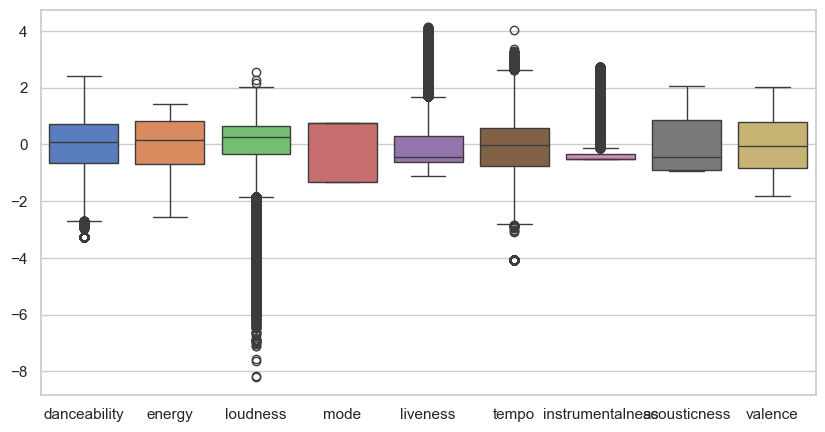

In [5]:
# Your code here
X.describe()
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
sns.boxplot(data=X_scaled)

#Göra clustering utan scaling, med scaling 1, med scaling 2 för att testa





1.there is some differences, especaiilly tempo has a big std. Tempo drar upp som in i bommben och loudness...

### Exercise 1.4 *** — StandardScaler vs MinMaxScaler

Try scaling with `MinMaxScaler` as well (scales everything to 0-1). Compare:
- How does MinMaxScaler handle outliers differently than StandardScaler?
- When might you prefer one over the other?

*Hint: StandardScaler is sensitive to outliers because it uses mean/std. MinMaxScaler is even more sensitive because a single extreme value stretches the range.*

<Axes: >

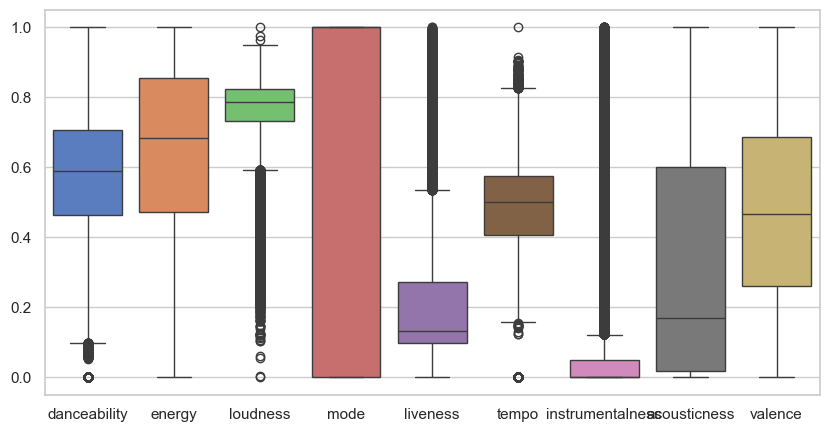

In [6]:
# Your code here
scaler2 = MinMaxScaler()
X_scaled2 = pd.DataFrame(scaler2.fit_transform(X), columns=X.columns)
sns.boxplot(data=X_scaled2)



### Git checkpoint — commit the shared foundation

Before branching, everyone should have the same starting point:

```bash
git add unsupervised_ml_workshop.ipynb
git commit -m "Complete Part 1: data preparation and scaling"
git add eda_workshop.ipynb
```

Make sure everyone pulls:
```bash
git pull origin main
```

---

---
## Part 2: Clustering Experiments (~45 min)

### Branch out!

Each group member picks **one** algorithm and creates a branch for it:

| Algorithm | Branch name | Key idea |
|-----------|-------------|----------|
| K-Means | `experiment/kmeans` | Partition into fixed K clusters by minimizing within-cluster distance |
| Agglomerative | `experiment/agglomerative` | Build a hierarchy of clusters bottom-up, visualize as dendrogram |
| DBSCAN | `experiment/dbscan` | Group by density, automatically detect noise/outliers |

```bash
git checkout -b experiment/<your-algorithm>
```

From here on, **work on your own branch**. You will all work in the same notebook but on different exercises below. When you are done, you will each commit and push your branch, then open a Pull Request.

---

### 2A: K-Means Clustering

*Work on branch `experiment/kmeans`*

#### Exercise 2A.1 * — Run K-Means

Fit K-Means with an initial guess for `k` (try k=3):

```python
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
```

1. Add the cluster labels to your dataframe
2. How many points ended up in each cluster?
3. Pick two features and create a scatter plot colored by cluster label

Useful: `sns.scatterplot(hue=...)`, `.value_counts()`

In [7]:
# Your code here

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

df["kmeans_cluster"] = labels

df["kmeans_cluster"].value_counts()



kmeans_cluster
1    41347
0    28364
2    24325
4    12386
3     7577
Name: count, dtype: int64

<Axes: xlabel='energy', ylabel='valence'>

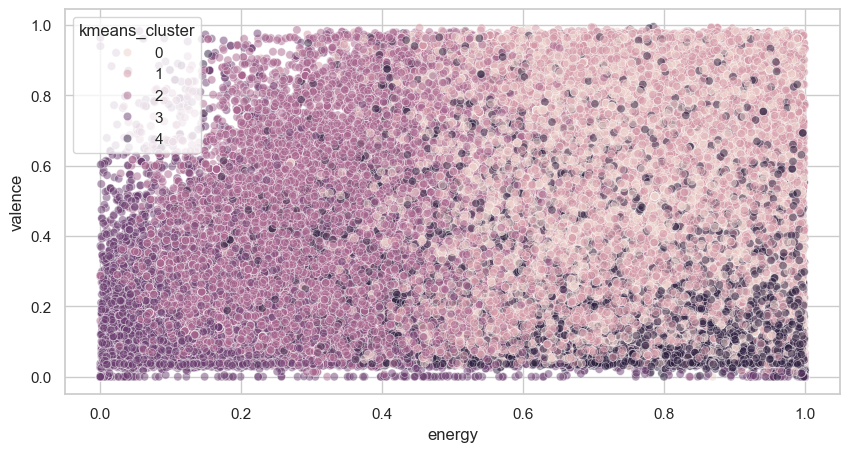

In [8]:
import seaborn as sns

sns.scatterplot(
    data=df,
    x="energy",
    y="valence",
    hue="kmeans_cluster",
    alpha=0.5
)

In [9]:
#K-means clustering med k=3 delar upp låtarna i tre grupper av olika storlek. 
# Vid visualisering med energy och valence ser vi att klustren främst separeras längs energy-axeln, vilket tyder på att energinivå är en viktig faktor i hur låtarna grupperas. 
# Valence varierar inom klustren och bidrar mindre till separationen i denna visualisering.


#### Exercise 2A.2 ** — The Elbow Method

How do you choose the right number of clusters? The **elbow method** plots the within-cluster sum of squares (inertia) for different values of K:

1. Run K-Means for k = 2, 3, 4, ..., 10
2. For each k, record `kmeans.inertia_`
3. Plot k vs. inertia — look for the "elbow" where adding more clusters stops helping much

What value of k does the elbow suggest?


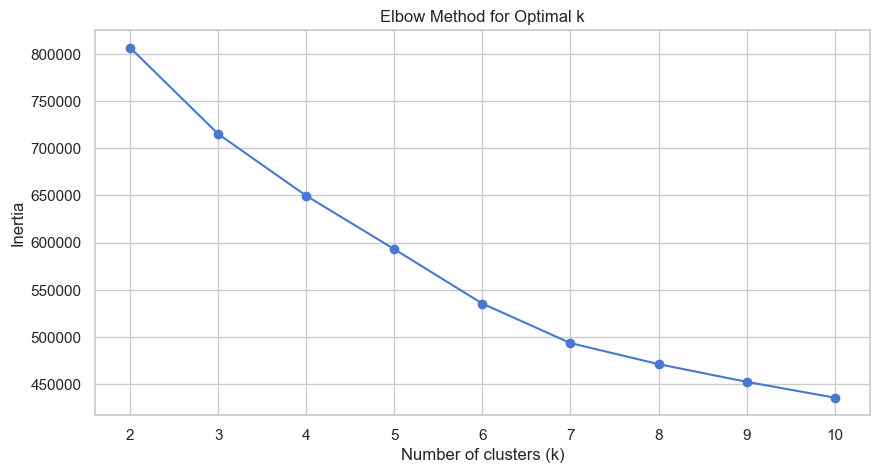

In [10]:
# Your code here

inertias = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(K, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [11]:
#Inertia minskar kraftigt när antalet kluster ökar från 2 till cirka 4–5, men därefter planar förbättringen ut. 
# Detta tyder på att det optimala antalet kluster ligger runt 4 eller 5.


#### Exercise 2A.3 ** — Silhouette Score

The silhouette score measures how similar each point is to its own cluster vs. the nearest neighboring cluster. It ranges from -1 (wrong cluster) to +1 (well-clustered).

1. Calculate the silhouette score for your chosen k: `silhouette_score(X_scaled, labels)`
2. Also calculate it for other values of k — does the best silhouette score agree with the elbow?
3. *Optional:* Create a silhouette plot showing per-sample scores

In [12]:
# Your code here

from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

score = silhouette_score(X_scaled, labels)
print("Silhouette score (k=2):", score)

Silhouette score (k=2): 0.18438217926694303


In [13]:
# Silhouette score är relativt låg (~0.19) och förändras inte mycket mellan olika värden på k. 
#Detta tyder på att datan inte innehåller tydligt separerade kluster. 
#Detta är rimligt för musikdata, där egenskaper varierar kontinuerligt snarare än att bilda distinkta grupper. 
#Därför väljs k=5 främst för tolkbarhet snarare än optimal klusterseparation.
# K=3: 0,17 , K=4:0,17, K=5: 0,18 , K=6: 0,2: 
    

#### Exercise 2A.4 ** — Interpret the clusters

Clusters are only useful if they *mean something*:

1. Group the **original (unscaled)** data by cluster label and compute the mean of each feature
2. Can you give each cluster a descriptive name? (e.g., "high-income low-spenders")
3. Visualize the cluster centers as a heatmap or bar chart

*Important: interpret using the original scale, not the scaled values — those are harder to reason about.*

In [14]:
# Your code here

df.groupby("kmeans_cluster")[feature_cols].mean()


,danceability,energy,loudness,mode,liveness,tempo,instrumentalness,acousticness,valence
kmeans_cluster,,,,,,,,,
0,0.615332,0.750783,-6.111367,0.000000,0.219618,124.548214,0.025500,0.169872,0.534858
1,0.590077,0.770524,-5.882477,1.000000,0.235579,128.007225,0.019454,0.156259,0.563849
2,0.538506,0.383413,-10.763916,0.808304,0.194090,112.495789,0.029545,0.689296,0.414850
3,0.345635,0.173502,-21.130036,0.642075,0.167988,102.953630,0.774549,0.863176,0.183092
4,0.568825,0.752612,-8.316803,0.549572,0.192243,127.787427,0.781089,0.105970,0.329433


In [15]:
cluster_names = {
    0: "Mainstream energetic / pop party",
    1: "Happy party / upbeat pop",
    2: "SChill / soft indie / relaxed music",
    3: "Ambient / instrumental / deep chill / background music",
    4: "Electronic / EDM / instrumental dance"
}

df["cluster_name"] = df["kmeans_cluster"].map(cluster_names)

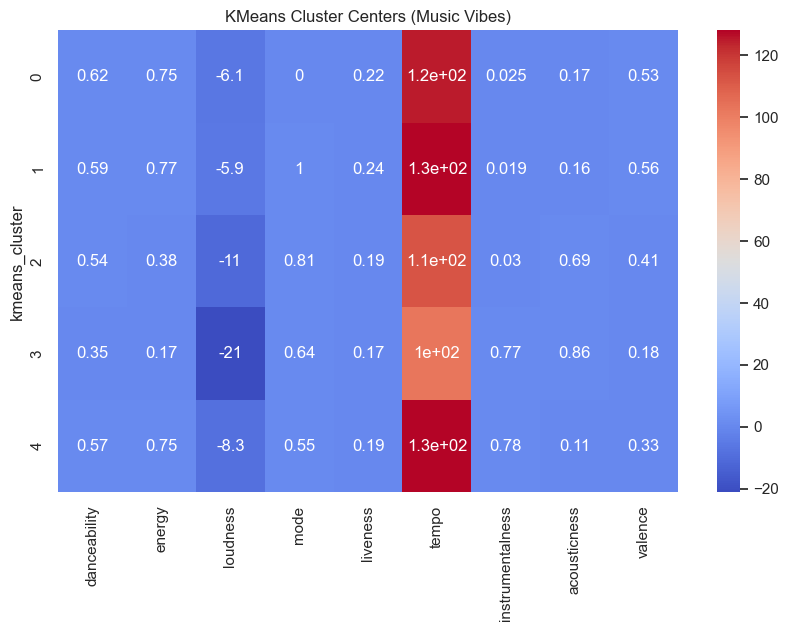

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

cluster_centers = df.groupby("kmeans_cluster")[feature_cols].mean()

plt.figure(figsize=(10,6))
sns.heatmap(cluster_centers, annot=True, cmap="coolwarm")
plt.title("KMeans Cluster Centers (Music Vibes)")
plt.show()

In [17]:
#För att tolka klustren grupperades originaldatan efter kluster och medelvärdet för varje feature beräknades. 
#Detta gjorde det möjligt att identifiera typiska egenskaper för varje grupp. 
#Baserat på dessa profiler gavs klustren beskrivande namn, såsom ‘Happy party / upbeat pop’ och ‘Chill / soft indie’, vilket gör resultaten mer tolkbara och användbara. 
#En heatmap användes för att visualisera skillnaderna mellan klustren.


#### Exercise 2A.5 *** — K-Means limitations

K-Means assumes clusters are spherical and roughly equal-sized. Try to show a case where it struggles:

1. If your data has clusters of very different sizes or non-spherical shapes, visualize where K-Means makes mistakes
2. *Optional:* Generate the `two_moons` toy dataset and show K-Means failing:
   ```python
   from sklearn.datasets import make_moons
   X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=42)
   ```

Document your findings — this will be valuable for the group comparison.

In [18]:
# Your code here
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=42)

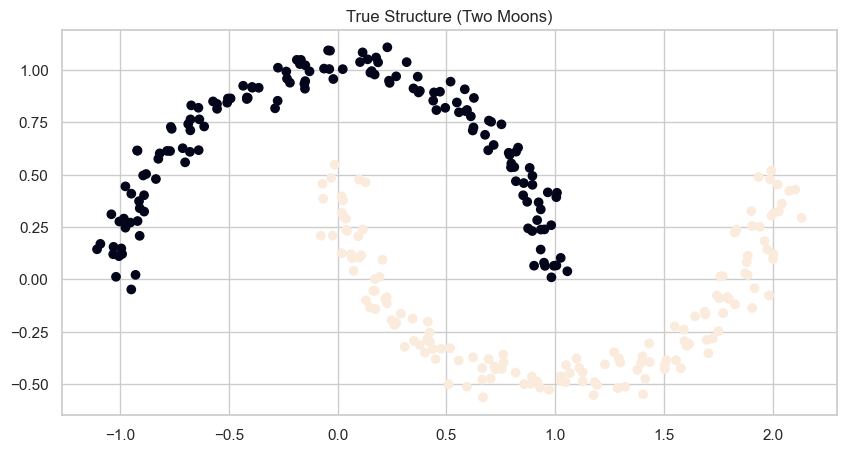

In [19]:
plt.scatter(X_moons[:,0], X_moons[:,1], c=y_moons)
plt.title("True Structure (Two Moons)")
plt.show()

In [20]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_moons)

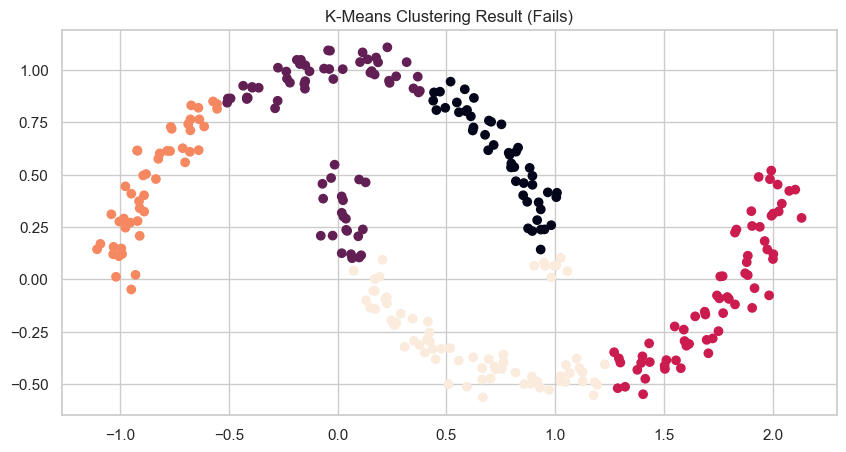

In [21]:
plt.scatter(X_moons[:,0], X_moons[:,1], c=labels)
plt.title("K-Means Clustering Result (Fails)")
plt.show()

---
### 2B: Agglomerative (Hierarchical) Clustering

*Work on branch `experiment/agglomerative`*

#### Exercise 2B.1 * — Build a dendrogram

Before running the clustering, visualize the hierarchy:

```python
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()
```

1. Look at the dendrogram — where would you "cut" it to form clusters?
2. How many clusters does the structure suggest?

*Recall from the lecture: you can cut the dendrogram at different heights to get different numbers of clusters.*

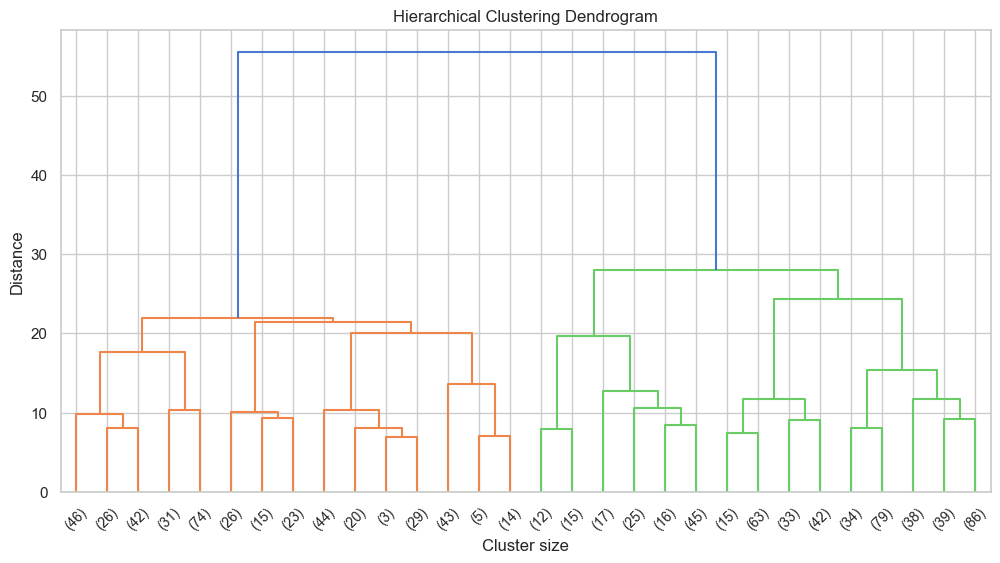

In [22]:
# Your code here
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

X_sample = X_scaled[:1000]



Z = linkage(X_sample, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

In [23]:
#Dendrogrammet visar hur datapunkter slås ihop steg för steg. Genom att ‘klippa’ trädet vid en viss höjd kan vi bestämma antal kluster. 
#I grafen syns ett tydligt hopp högt upp, vilket tyder på att 2 huvudsakliga kluster är rimligt.


#### Exercise 2B.2 * — Run Agglomerative Clustering

Now cluster with the number of clusters you chose from the dendrogram:

```python
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = agg.fit_predict(X_scaled)
```

1. Add the cluster labels to your dataframe
2. How many points in each cluster?
3. Create a scatter plot colored by cluster label

In [24]:
# Your code here
# Your code here

X_sample = X_scaled[:2000]
df_sample = df.iloc[:2000].copy()


agg = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels = agg.fit_predict(X_sample)

df_sample["agg_cluster"] = labels

df_sample["agg_cluster"].value_counts()

agg_cluster
0    1282
1     718
Name: count, dtype: int64

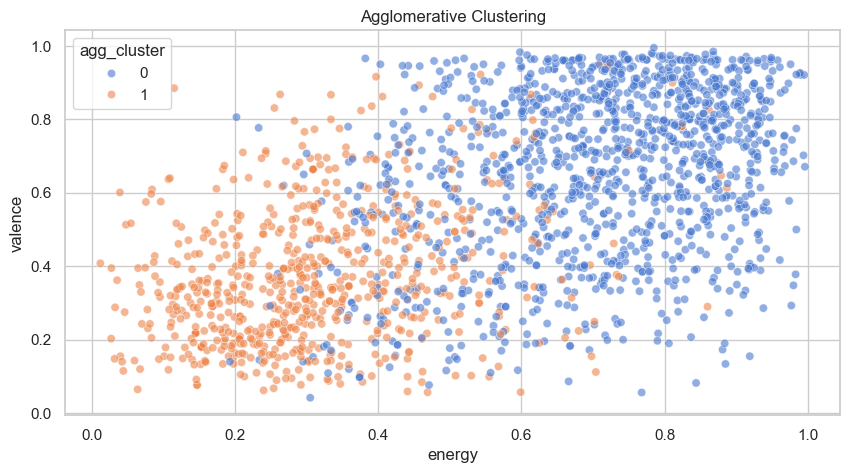

In [25]:
sns.scatterplot(
    data=df_sample,
    x="energy",
    y="valence",
    hue="agg_cluster",
    alpha=0.6
)

plt.title("Agglomerative Clustering")
plt.show()

In [26]:
# Vi använde Agglomerative Clustering med 2 kluster baserat på dendrogrammet. 
#Resultatet visar att datapunkterna delas upp i två grupper av olika storlek. 
#Genom att visualisera klustren med en scatter plot (energy vs valence) kan vi se hur låtarna grupperas baserat på deras egenskaper.


#### Exercise 2B.3 ** — Experiment with linkage methods

The linkage method defines how the distance between clusters is measured. Try different methods and compare the dendrograms:

- `ward` — minimizes within-cluster variance (tends to produce equal-sized clusters)
- `complete` — maximum distance between clusters
- `average` — average distance between clusters
- `single` — minimum distance (can produce long, chain-like clusters)

1. Plot dendrograms for at least two different linkage methods side by side
2. How do the resulting cluster structures differ?
3. Which linkage method seems best for your data?

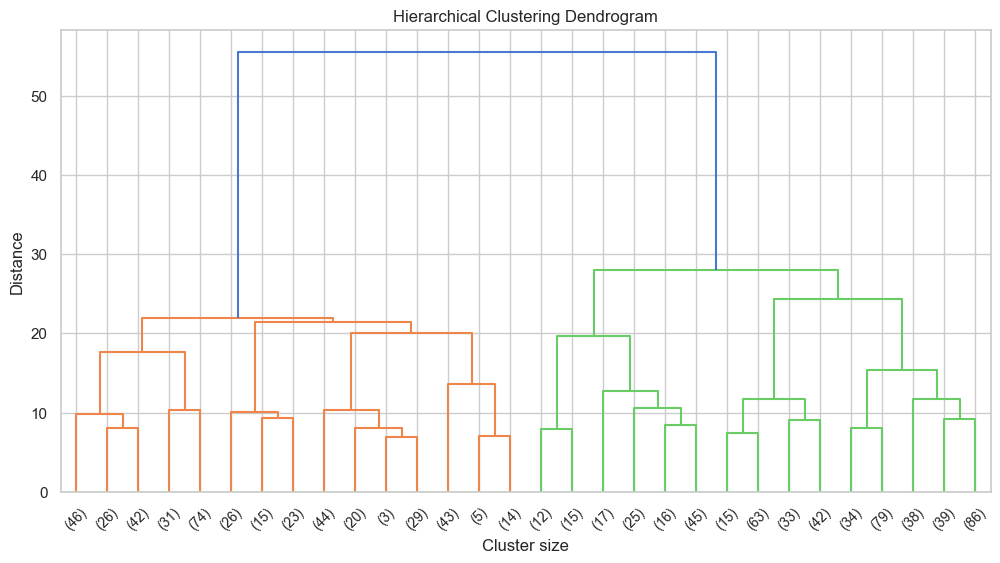

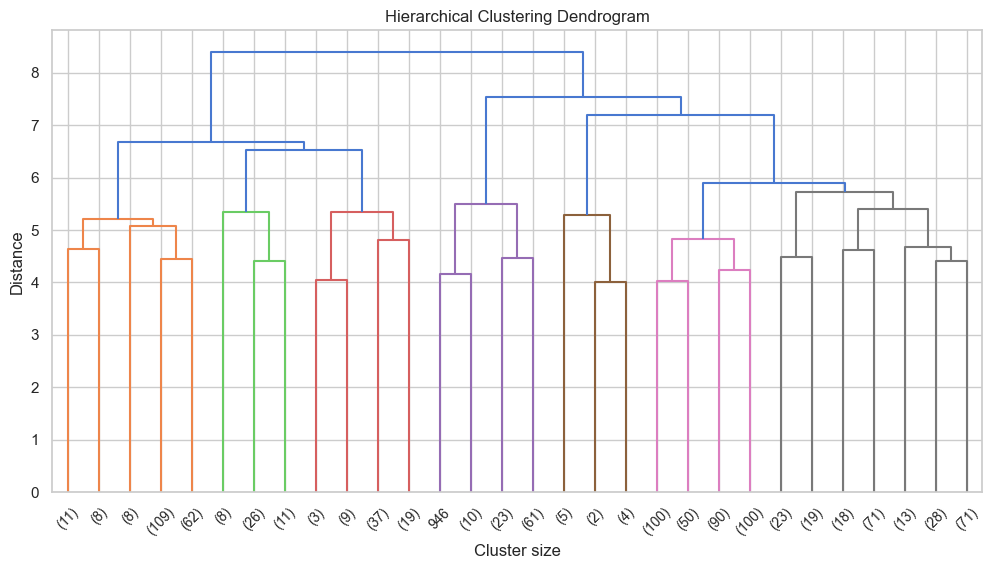

In [27]:
# Your code here
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

X_sample = X_scaled[:1000]  # viktigt så kernel inte dör


Z = linkage(X_sample, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

Z = linkage(X_sample, method='complete')
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()


In [28]:
#Resultatet visar att metoderna ger olika typer av dendrogram och därmed olika sätt att gruppera datapunkterna. 
#Ward linkage skapar tydliga och kompakta kluster med ett stort avstånd mellan huvudgrupperna, vilket gör det lätt att avgöra var man kan “klippa” trädet. 
#Complete linkage håller kluster mer separerade men kan bli känslig för extrema värden. 

#### Exercise 2B.4 ** — Silhouette Score & Interpretation

1. Calculate the silhouette score for your clustering
2. Try different numbers of clusters (2-8) and plot k vs. silhouette score
3. Group the **original (unscaled)** data by cluster and compute means — can you name the clusters?

In [29]:
# Your code here

from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

scores = []
K = range(2, 9)

X_sample = X_scaled[:2000]

for k in K:
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = agg.fit_predict(X_sample)
    
    score = silhouette_score(X_sample, labels)
    scores.append(score)
    print(f"k={k}, score={score:.3f}")

k=2, score=0.227
k=3, score=0.203
k=4, score=0.194
k=5, score=0.192
k=6, score=0.186
k=7, score=0.189
k=8, score=0.196


In [30]:
# Vi beräknade silhouette score för olika antal kluster (k=2–8) för att utvärdera kvaliteten på klustringen. 
# Resultatet visar att k=2 ger högst score (0.260), vilket indikerar den bästa separationen mellan kluster. 
# När antalet kluster ökar minskar silhouette score, vilket tyder på att strukturen blir mindre tydlig. 
# Detta bekräftar tidigare observationer från dendrogrammet att två kluster är ett rimligt val.

#### Exercise 2B.5 *** — Pros and cons in practice

Agglomerative clustering doesn't require specifying k in advance (you can read it from the dendrogram), but it is slower on large datasets.

1. If your dataset is large, time the clustering: `%%timeit` or `import time`
2. Compare with K-Means on the same data — which is faster?
3. When would you choose agglomerative over K-Means?

Document your findings for the group comparison.

In [31]:
# Your code here


---
### 2C: DBSCAN

*Work on branch `experiment/dbscan`*

#### Exercise 2C.1 * — Run DBSCAN

DBSCAN needs two parameters instead of the number of clusters:
- `eps` — the maximum distance between two points to be considered neighbors
- `min_samples` — how many neighbors a point needs to be a core point

Start with default-ish values:

```python
dbscan = DBSCAN(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)
```

1. Add labels to your dataframe. Note: label `-1` means **noise** (outlier)
2. How many clusters were found? How many noise points?
3. Create a scatter plot — color clusters normally, mark noise points distinctly

Antal kluster som hittades: 1226
Antal bruspunkter (outliers): 52129


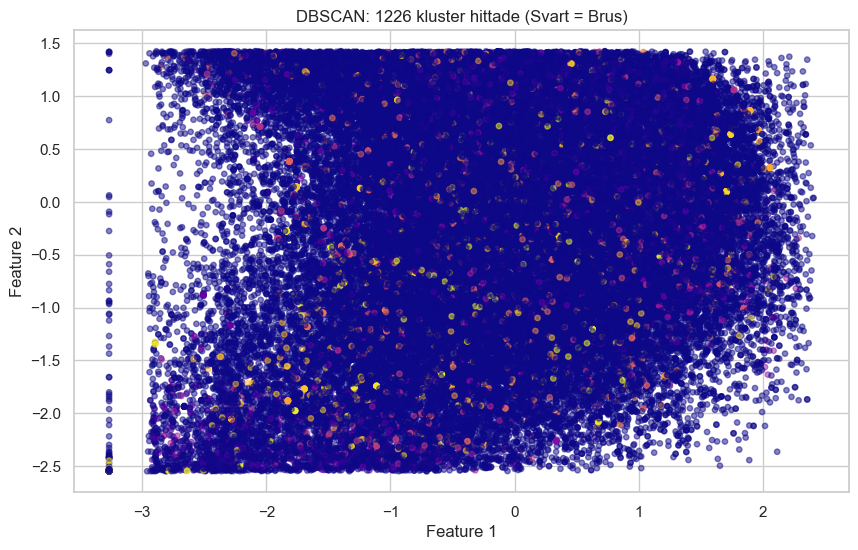

In [32]:
# Your code here
dbscan = DBSCAN(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

# Hitta alla unika labels
unique_labels = set(labels)

# Räkna antal kluster (ta bort 1 om -1 finns med i setet)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Räkna hur många punkter som är brus (-1)
n_noise = list(labels).count(-1)

df['cluster'] = labels

print(f"Antal kluster som hittades: {n_clusters}")
print(f"Antal bruspunkter (outliers): {n_noise}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Vi mappar färger: Alla som INTE är -1 får en färg, -1 (brus) blir svart
# Vi antar att X_scaled är en numpy-array med minst 2 kolumner
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], 
            c=labels, 
            cmap='plasma', 
            s=15, 
            alpha=0.5)

plt.title(f"DBSCAN: {n_clusters} kluster hittade (Svart = Brus)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [33]:
#Testar som sagt algoritmen för att objektivt se vilka artister som tillhör ett visst kluster. Denna modell tittar på vart datapuntkernana ligger och utifrån radien ser den vilka som är nära varandra eller inte. Om man radien är för hög kommer låtar , som kanske är för olika varandra, komma i samma kluster och vice versa.

#Samples visar på att vi letar efter kluster där minst 5 låtar ligger nära varandra. Inom 0.5 (eps).

#Med de värdena blir det för många kluster och för mycket "unika" resultat.
# -1226 antal kluster, och 52129 bruspunkter.

#### Exercise 2C.2 ** — Tuning eps with a k-distance plot

Choosing `eps` is the hardest part of DBSCAN. The **k-distance plot** helps:

1. For each point, compute the distance to its k-th nearest neighbor (use k = `min_samples`)
2. Sort these distances and plot them
3. Look for an "elbow" — this suggests a good value for `eps`

```python
from sklearn.neighbors import NearestNeighbors

k = 5
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.plot(k_distances)
plt.ylabel(f'{k}-th nearest neighbor distance')
plt.xlabel('Points (sorted)')
plt.title('k-Distance Plot')
plt.show()
```

Re-run DBSCAN with the eps you chose from the plot. Did the results improve?

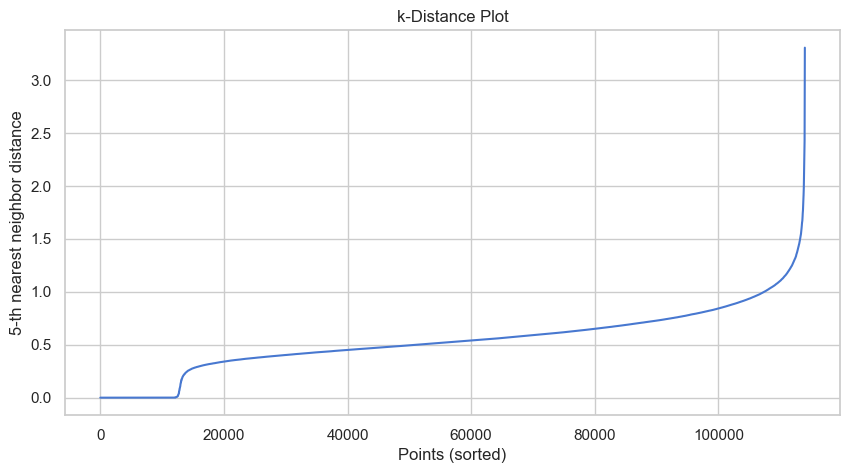

In [34]:
# Your code here
from sklearn.neighbors import NearestNeighbors

k = 5
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.plot(k_distances)
plt.ylabel(f'{k}-th nearest neighbor distance')
plt.xlabel('Points (sorted)')
plt.title('k-Distance Plot')
plt.show()


In [35]:
#-Fram till 100 000 låtar ligger flesta låtarna tätt. De har ett kort avstånd till sina grannar. 
#-Efter 0.6 stiger den , där punkterna blir väldigt långt från sina grannar.

#### Exercise 2C.3 ** — Sensitivity to parameters

DBSCAN results can change dramatically with different `eps` and `min_samples`. Explore this:

1. Try at least 3 different combinations of `eps` and `min_samples`
2. For each, record: number of clusters found, number of noise points, silhouette score (excluding noise)
3. Visualize the results side by side

*When calculating silhouette score with DBSCAN, exclude noise points (label == -1), since they are not assigned to any cluster.*

Antal kluster som hittades: 22
Antal bruspunkter (outliers): 9494


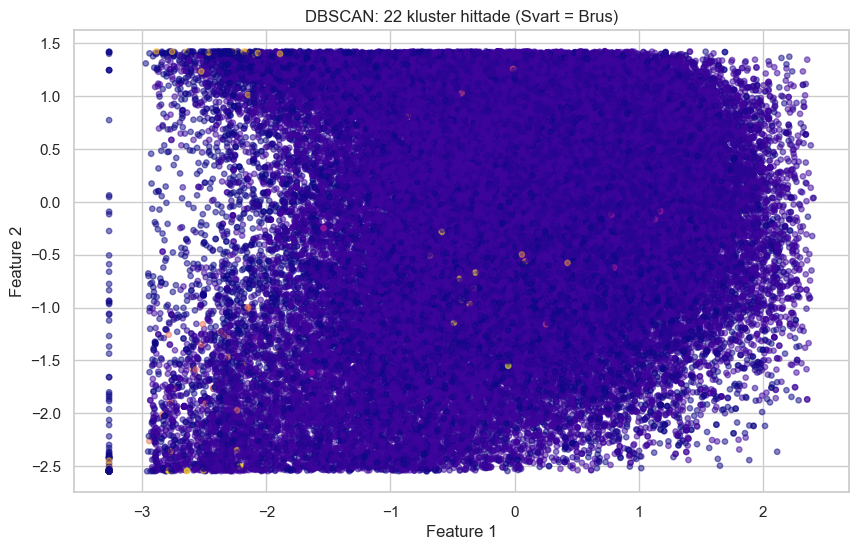

In [36]:
# Your code here
# test 1

dbscan = DBSCAN(eps=0.9, min_samples=10)
labels = dbscan.fit_predict(X_scaled)

# Hitta alla unika labels
unique_labels = set(labels)

# Räkna antal kluster (ta bort 1 om -1 finns med i setet)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Räkna hur många punkter som är brus (-1)
n_noise = list(labels).count(-1)

df['cluster'] = labels

print(f"Antal kluster som hittades: {n_clusters}")
print(f"Antal bruspunkter (outliers): {n_noise}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Vi mappar färger: Alla som INTE är -1 får en färg, -1 (brus) blir svart
# Vi antar att X_scaled är en numpy-array med minst 2 kolumner
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], 
            c=labels, 
            cmap='plasma', 
            s=15, 
            alpha=0.5)

plt.title(f"DBSCAN: {n_clusters} kluster hittade (Svart = Brus)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Antal kluster som hittades: 2
Antal bruspunkter (outliers): 3384


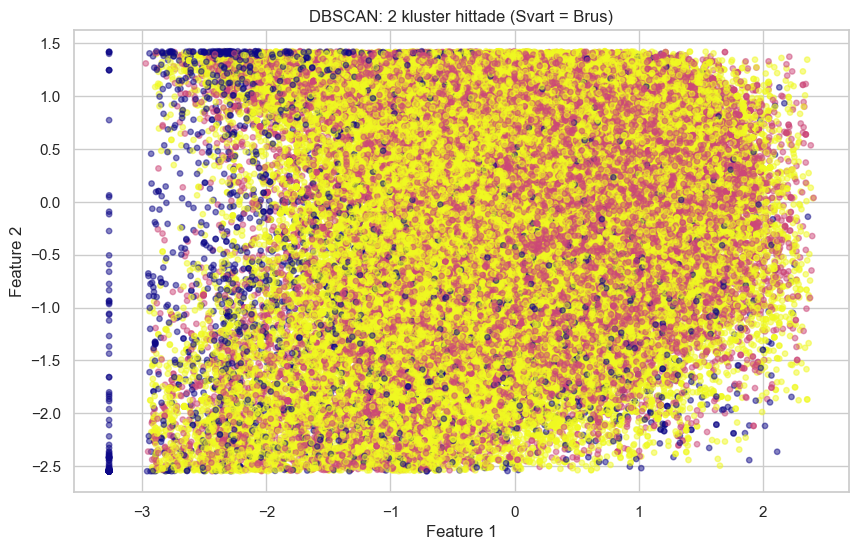

In [37]:
# test 2

dbscan = DBSCAN(eps=1.2, min_samples=25)
labels = dbscan.fit_predict(X_scaled)

# Hitta alla unika labels
unique_labels = set(labels)

# Räkna antal kluster (ta bort 1 om -1 finns med i setet)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Räkna hur många punkter som är brus (-1)
n_noise = list(labels).count(-1)

df['cluster'] = labels

print(f"Antal kluster som hittades: {n_clusters}")
print(f"Antal bruspunkter (outliers): {n_noise}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Vi mappar färger: Alla som INTE är -1 får en färg, -1 (brus) blir svart
# Vi antar att X_scaled är en numpy-array med minst 2 kolumner
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], 
            c=labels, 
            cmap='plasma', 
            s=15, 
            alpha=0.5)

plt.title(f"DBSCAN: {n_clusters} kluster hittade (Svart = Brus)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Antal kluster som hittades: 6
Antal bruspunkter (outliers): 59957


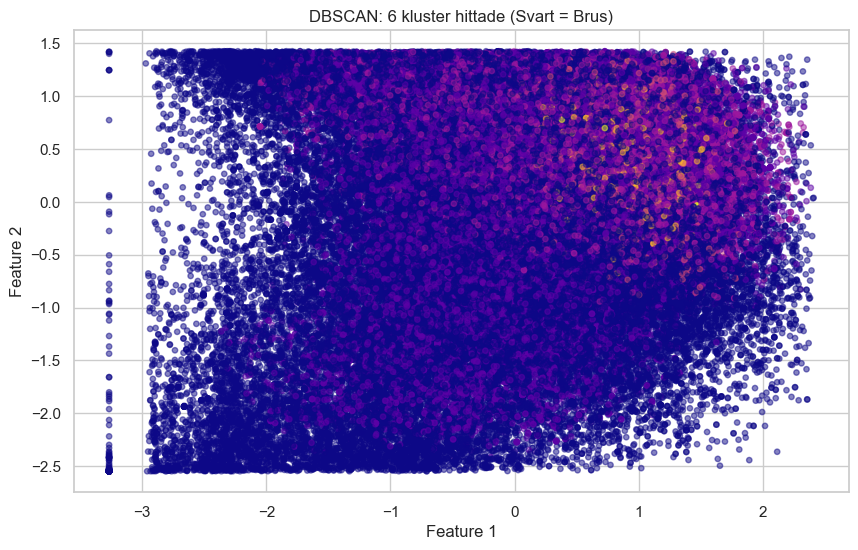

In [38]:
# test 3

dbscan = DBSCAN(eps=0.8, min_samples=150)
labels = dbscan.fit_predict(X_scaled)

# Hitta alla unika labels
unique_labels = set(labels)

# Räkna antal kluster (ta bort 1 om -1 finns med i setet)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Räkna hur många punkter som är brus (-1)
n_noise = list(labels).count(-1)

df['cluster'] = labels

print(f"Antal kluster som hittades: {n_clusters}")
print(f"Antal bruspunkter (outliers): {n_noise}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Vi mappar färger: Alla som INTE är -1 får en färg, -1 (brus) blir svart
# Vi antar att X_scaled är en numpy-array med minst 2 kolumner
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], 
            c=labels, 
            cmap='plasma', 
            s=15, 
            alpha=0.5)

plt.title(f"DBSCAN: {n_clusters} kluster hittade (Svart = Brus)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Antal kluster som hittades: 4
Antal bruspunkter (outliers): 10327


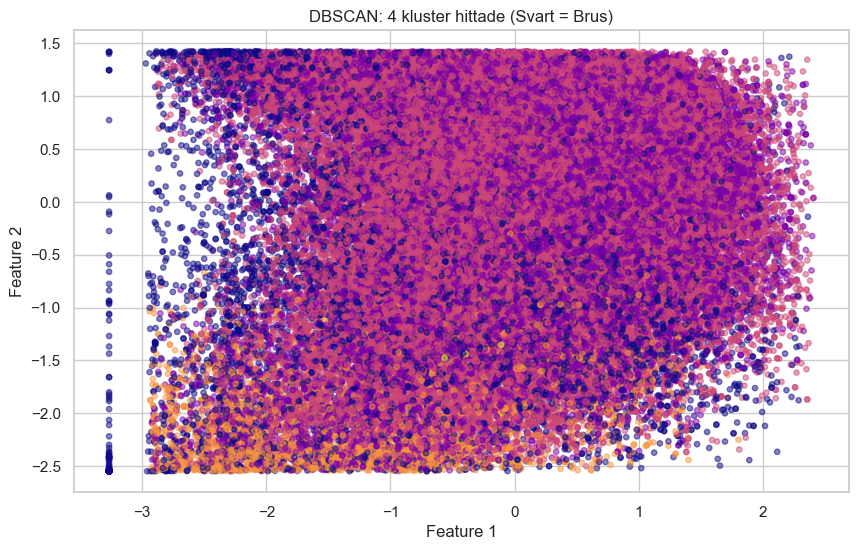

In [39]:
#test 4

dbscan = DBSCAN(eps=1.0, min_samples= 28)
labels = dbscan.fit_predict(X_scaled)

# Hitta alla unika labels
unique_labels = set(labels)

# Räkna antal kluster (ta bort 1 om -1 finns med i setet)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Räkna hur många punkter som är brus (-1)
n_noise = list(labels).count(-1)

df['cluster'] = labels

print(f"Antal kluster som hittades: {n_clusters}")
print(f"Antal bruspunkter (outliers): {n_noise}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Vi mappar färger: Alla som INTE är -1 får en färg, -1 (brus) blir svart
# Vi antar att X_scaled är en numpy-array med minst 2 kolumner
plt.scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], 
            c=labels, 
            cmap='plasma', 
            s=15, 
            alpha=0.5)

plt.title(f"DBSCAN: {n_clusters} kluster hittade (Svart = Brus)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [40]:
#-När man visualiserar på detta sättet ser det enbart ut som ett fyllt moln, vilket gör det svårt att tolka. Pågrund av att det är så många datapunkter som ligger nära varandra. Sedan visualiserar scatter enbart på två features och många punkter ligger nära inom många egenskaper, därmed är det förståeligt att resultaten är tätt.

#-Den sista testet var väl bäst antal kluster, testade dessutom att titta på outliers och deras genrer, vilket verkar väldigt förståeligt.

In [41]:
from sklearn.metrics import silhouette_score

# Ta bort brus/outliers (-1) innan silhouette score
mask = labels != -1
X_no_noise = X_scaled[mask]
labels_no_noise = labels[mask]

# Silhouette kräver minst 2 kluster
if len(set(labels_no_noise)) >= 2:
    score = silhouette_score(X_no_noise, labels_no_noise)
    print("Silhouette score (DBSCAN):", score)
else:
    print("Silhouette score kan inte beräknas: DBSCAN hittade färre än 2 kluster utan brus.")


Silhouette score (DBSCAN): 0.13768792623427592


#### Exercise 2C.4 ** — Interpret the clusters and noise

1. Group the **original (unscaled)** data by cluster label (excluding noise) and compute means
2. Look at the noise points separately — do they share any characteristics? Are they genuine outliers?
3. Can you name the clusters?

In [42]:
# Your code here
# 1. Läs in originalfilen
df_original = pd.read_csv('spotify_tracks (kopia).csv')

# samma rensning 
df_original = df_original.dropna() 

# Nu ska längderna matcha och lägga till kolumnerna
df_original['cluster'] = labels 

# Gruppera
print(df_original[df_original['cluster'] != -1].groupby('cluster')['track_genre'].agg(lambda x: x.value_counts().index[0]))

# Beräkna medelvärden för vibe-kolumnerna per kluster (exkludera brus)
vibe_means = df_original[df_original['cluster'] != -1].groupby('cluster')[feature_cols].mean()
print(vibe_means)

cluster
0       turkish
1    honky-tonk
2       new-age
3       country
Name: track_genre, dtype: str
         danceability    energy   loudness  mode  liveness       tempo  \
cluster                                                                  
0            0.596072  0.685051  -7.431444   0.0  0.187536  122.129523   
1            0.576063  0.662469  -7.326872   1.0  0.205493  123.329574   
2            0.372639  0.144557 -21.178855   1.0  0.115426  102.153088   
3            0.474061  0.238606 -14.811788   1.0  0.711485  135.307424   

         instrumentalness  acousticness   valence  
cluster                                            
0                0.139786      0.248608  0.476175  
1                0.074502      0.294918  0.501900  
2                0.884755      0.921110  0.188836  
3                0.004726      0.812879  0.343515  


In [43]:
#titta på outliners 

df_noise = df_original[df_original['cluster'] == -1]
print(df_noise['track_genre'].value_counts().head(10))

track_genre
sleep        613
study        496
comedy       446
iranian      355
idm          329
classical    284
new-age      241
tango        234
guitar       232
grindcore    221
Name: count, dtype: int64


In [44]:
# titta på klusterna och exemepl på låtar

counts = df_original['cluster'].value_counts()
print("Följande kluster hittades i datan:")
print(counts)

print("\n--- STARTAR EXEMPEL-UTSKRIFT ---")
# Vi tar bort 'if cluster_id == -1' för att se ALLT
for cluster_id in sorted(df_original['cluster'].unique()):
    print(f"--- FÖRSÖKER HÄMTA FRÅN KLUSTER {cluster_id} ---")
    
    exempel = df_original[df_original['cluster'] == cluster_id]
    
    if len(exempel) > 0:
        # Ta 5 låtar, eller färre om klustret är litet
        n = min(len(exempel), 5)
        print(exempel[['artists', 'track_name', 'track_genre']].sample(n))
    else:
        print("Hittade inga rader för detta kluster i df_original.")
    print("\n")

Följande kluster hittades i datan:
cluster
 1    63632
 0    36603
-1    10327
 2     3404
 3       33
Name: count, dtype: int64

--- STARTAR EXEMPEL-UTSKRIFT ---
--- FÖRSÖKER HÄMTA FRÅN KLUSTER -1 ---
                       artists                     track_name track_genre
94300   Timmies;Shiloh Dynasty                      Soft Skin         sad
108096            Tita Merello       Los Amores con la Crisis       tango
34977              John Denver            Rocky Mountain High        folk
15665                      VAL  Something Isn't Right With Us       chill
18466          Stuart Thompson                Xmas Card Photo      comedy


--- FÖRSÖKER HÄMTA FRÅN KLUSTER 0 ---
                      artists                           track_name  \
107827           Alison Moyet           That Ole Devil Called Love   
6791          Old Man's Child               Enslaved and Condemned   
109745               Josement  My Battery Is Hungry - Original Mix   
105164  Sless Praismo;Mosalla     

In [45]:
#1.Titta på grupperna, där 0 och 1 egentligen hade ganska lika väden, de som skiljer är om låtarna går i dur och moll. 
#2.Kolla på outliners, vilket ändå make sense. Bland anant natur ljud och speciella låtar/genrer 
#3.Namnen som valdes verkade inte helt stämma överens, därmed ändrade vi dem.

#Nya namn: 0 “Hög energi & glad” / “Party & Drive” 1 “Groovy & balanserad” / “Feelgood mix” 2 “Lugn & låg energi” / “Chill & Ambient” 3 “Akustisk & lågintensiv” -1 “Outliers / Blandat”

#### Exercise 2C.5 *** — Where DBSCAN shines

DBSCAN can find clusters of arbitrary shape — something K-Means cannot do.

1. Generate the `two_moons` dataset and run DBSCAN on it:
   ```python
   from sklearn.datasets import make_moons
   X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=42)
   ```
2. Compare the DBSCAN result with K-Means (k=2) on the same data
3. Which algorithm recovers the true shape?

Document your findings for the group comparison.

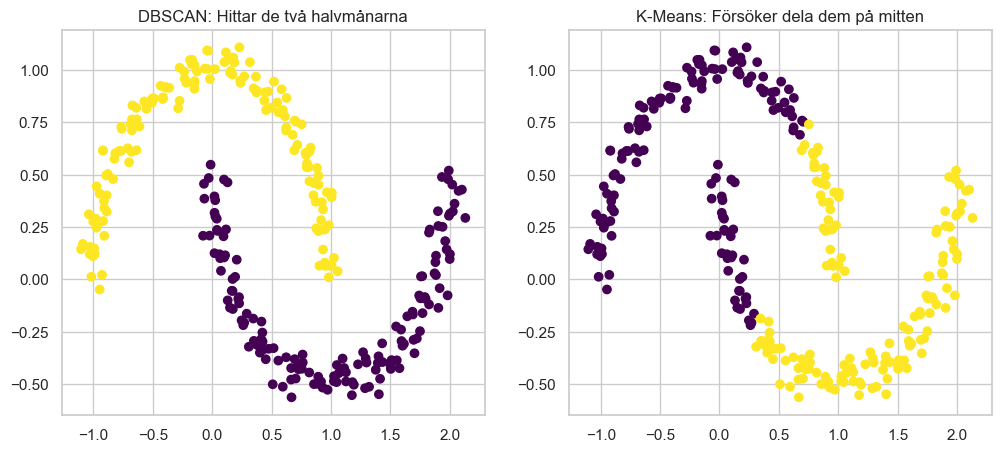

In [46]:
# Your code here
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans

# 1. Generera datasetet
X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=42)

# 2. Kör DBSCAN (Du kan behöva leka lite med eps, testa 0.2 till 0.3)
dbscan = DBSCAN(eps=0.15, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_moons)

# 3. Kör K-Means (med k=2) för jämförelse
kmeans = KMeans(n_clusters=2, random_state=42)
labels_kmeans = kmeans.fit_predict(X_moons)

# 4. Visualisera resultaten bredvid varandra
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot DBSCAN
ax1.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_dbscan, cmap='viridis')
ax1.set_title('DBSCAN: Hittar de två halvmånarna')

# Plot K-Means
ax2.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_kmeans, cmap='viridis')
ax2.set_title('K-Means: Försöker dela dem på mitten')

plt.show()

### Git checkpoint — push your experiment branch

Commit your work and push your branch:

```bash
git add unsupervised_ml_workshop.ipynb
git commit -m "Complete experiment: <your-algorithm>"
git push -u origin experiment/<your-algorithm>
```

---

---
## Part 3: Pull Requests & Comparison (~20 min)

Now comes the collaborative part. Each member has run a different experiment on their own branch — time to compare.

### Step 1 — Open a Pull Request

Each member opens a PR from their experiment branch to `main`:

1. Go to the fork on GitHub
2. Click **"Compare & pull request"** for your branch
3. Title: `Experiment: <Algorithm Name>`
4. In the description, include:
   - Number of clusters found
   - Silhouette score
   - One key strength of this algorithm on your data
   - One limitation you noticed

### Step 2 — Review each other's PRs

Read your groupmates' PRs and leave at least one comment:
- Do their clusters make sense?
- Did they find different groupings than you?
- Any suggestions or questions?

### Step 3 — Merge the PRs

After reviewing, merge all PRs into `main`. If there are merge conflicts in the notebook, resolve them together.

*This mirrors how data science teams work: parallel experiments on branches, comparison through PRs, best approach merged into the main codebase.*

---

---
## Part 4: Synthesis (~15 min)

**Do this together as a group, back on `main`:**

```bash
git checkout main
git pull origin main
```

### Exercise 4.1 * — Comparison table

Fill in this table based on your group's experiments:

| | K-Means | Agglomerative | DBSCAN |
|---|---------|---------------|--------|
| Clusters found | 5 | 2 | 4 |
| Silhouette score | K=5: 0,18 | k=2: 0.227 | 0.18|
| Handles noise/outliers? | nej | nej | ja |
| Needs k specified? | ja | ja | nej |
| Cluster shapes | runda | flexibla | allt möjligt|
| Speed | snabb | långsam | kan vara båda |

Which algorithm worked best for your dataset, and why?

För ett stort dataset med låtar är KMeans oftast den mest lämpliga metoden eftersom den är skalbar och ger stabila klusterresultat. DBSCAN kan vara användbar för att identifiera avvikande eller ovanliga låtar (outliers), men metoden är känslig för val av parametrar och kan ha svårt att prestera bra i högdimensionell data. Agglomerativ klustring är mindre lämplig i detta fall eftersom den är beräkningsmässigt tung och därför inte fungerar lika bra på stora dataset.

*Fill in your comparison here*


### Exercise 4.2 ** — Side-by-side visualization

Create a figure with 3 subplots showing the same scatter plot (same two features) colored by each algorithm's labels. This makes the differences immediately visible.

```python
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Plot each algorithm's clusters on its own subplot
```

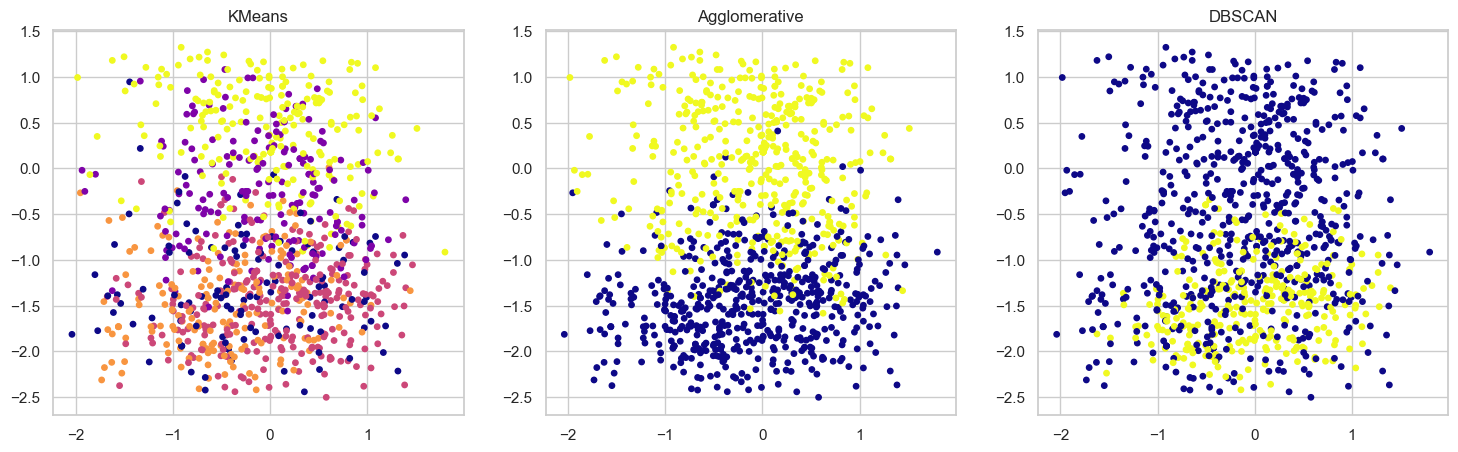

In [49]:
# Your code here


from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

X_sample = X_scaled[:1000]

# KMeans (5 kluster)
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_sample)

# Agglomerative (2 kluster)
agg = AgglomerativeClustering(n_clusters=2)
agg_labels = agg.fit_predict(X_sample)

# DBSCAN (försök få ~4 kluster)
dbscan = DBSCAN(eps=1.0, min_samples=28)
dbscan_labels = dbscan.fit_predict(X_sample)



fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_sample.iloc[:, 0], X_sample.iloc[:, 1],
                c=kmeans_labels, cmap='plasma', s=15)
axes[0].set_title("KMeans")

axes[1].scatter(X_sample.iloc[:, 0], X_sample.iloc[:, 1],
                c=agg_labels, cmap='plasma', s=15)
axes[1].set_title("Agglomerative")

axes[2].scatter(X_sample.iloc[:, 0], X_sample.iloc[:, 1],
                c=dbscan_labels, cmap='plasma', s=15)
axes[2].set_title("DBSCAN")

plt.show()

In [ ]:
#Resultaten visar tydliga skillnader mellan algoritmerna. 
#KMeans delar upp datan i flera mindre och mer detaljerade kluster, medan Agglomerative clustering ger en grövre uppdelning i endast två grupper. 
#DBSCAN identifierar kluster baserat på täthet, vilket resulterar i mer oregelbundna och naturliga klusterformer. 
#Detta visar att valet av algoritm påverkar hur datan grupperas och tolkas.


### Exercise 4.3 ** — Do the algorithms agree?

Check how much the algorithms agree on which points belong together:

1. Create a cross-tabulation between two algorithms' labels: `pd.crosstab(labels_kmeans, labels_dbscan)`
2. Where do they agree? Where do they disagree?
3. If you have a ground-truth label (e.g., species for penguins), which algorithm recovers it best?

In [50]:
# Your code here
import pandas as pd

ct_kmeans_dbscan = pd.crosstab(kmeans_labels, dbscan_labels)
print(ct_kmeans_dbscan)

col_0   -1    0
row_0          
0      122    0
1      175    7
2       79  207
3       98   94
4      218    0


In [51]:
ct_kmeans_agg = pd.crosstab(kmeans_labels, agg_labels)
print(ct_kmeans_agg)

col_0    0    1
row_0          
0      107   15
1       22  160
2      269   17
3      156   36
4        5  213


In [52]:
ct_agg_dbscan = pd.crosstab(agg_labels, dbscan_labels)
print(ct_agg_dbscan)

col_0   -1    0
row_0          
0      256  303
1      436    5


In [ ]:
#KMeans & Agglo → hög överensstämmelse
#DBSCAN → låg överensstämmelse
#anledning → noise + density

### Exercise 4.4 *** — What would you recommend?

Write a short recommendation (5-10 sentences) as if advising a colleague:

1. Which algorithm would you use for this dataset and why?
2. How many clusters do you recommend?
3. What are the clusters and what do they mean in the domain context?
4. What are the limitations of your analysis?
5. What would you try next?

*Write your recommendation here*


### Final commit

```bash
git add unsupervised_ml_workshop.ipynb
git commit -m "Complete synthesis: algorithm comparison"
git push origin main
```

---